# Exoplanet Habitable-Zone Analysis

**Data visualisation project · Python, Pandas, Seaborn, Matplotlib and Plotly**

*Revised from the author's Advanced Data Visualisation MSc assignment.*

**Research question.** Which confirmed exoplanets in a frozen Open Exoplanet Catalogue snapshot fall within a *simplified, luminosity-scaled circumstellar habitable-zone interval*?

> **Interpretation matters:** This geometric filter does **not** establish that a planet is habitable, has liquid water, or is Earth-like. This notebook demonstrates data cleaning, exploratory analysis and scientific uncertainty.

The source dataset is distributed with this project and documented in [`data/DATA_LICENSE.md`](../data/DATA_LICENSE.md). For the full derivation and limitations, see [`docs/METHODOLOGY.md`](../docs/METHODOLOGY.md).

## 1 · Setup and source data

Run this notebook from the repository root or its `notebooks/` folder. Source data are local; no API key or Internet connection is needed. The catalogue is a *historical snapshot* with discovery years through 2023.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
from IPython.display import display, Image

# Portable path handling: works when Jupyter starts from the repository root
# or its notebooks/ folder, instead of depending on the author's C: drive.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src" / "exoplanet_analysis.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook within the GitHub repository.")
sys.path.insert(0, str(ROOT / "src"))
from exoplanet_analysis import (
    load_catalogue, analyse_catalogue, confirmed_only,
    summary_counts, make_tables, write_outputs,
)

catalogue = load_catalogue()
print(f"Raw catalogue: {len(catalogue):,} rows × {catalogue.shape[1]} columns")
display(catalogue[['name','list','hoststar_mass','hoststar_radius',
                   'hoststar_temperature','semimajoraxis']].head(6))

Raw catalogue: 5,414 rows × 25 columns


,name,list,hoststar_mass,hoststar_radius,hoststar_temperature,semimajoraxis
0,Kepler-1032 b,Confirmed planets,0.770,0.71,4647.0,NaN
1,HD 154857 b,Confirmed planets,1.718,2.31,5508.0,1.291
2,HD 154857 c,Confirmed planets,1.718,2.31,5508.0,5.360
3,Kepler-994 b,Confirmed planets,0.560,0.54,3934.0,NaN
4,Kepler-1350 b,Confirmed planets,0.550,0.53,3827.0,NaN
5,Kepler-1350 c,Confirmed planets,0.550,0.53,3827.0,NaN


## 2 · Source quality and selection

The flat catalogue includes confirmed exoplanets alongside controversial objects, retracted candidates and Solar System bodies. We restrict the principal analysis to **confirmed exoplanet records** by parsing the dataset's exact `Confirmed planets` tag.

The three variables needed for a geometrical HZ estimate are **stellar radius**, **stellar temperature** and **orbital semi-major axis**. Missing values are neither zeroes nor negative outcomes.

In [2]:
fields = ['hoststar_radius','hoststar_temperature','semimajoraxis']
missing = catalogue[fields].isna().sum().rename('missing_records')
display(missing.to_frame())

analysed = analyse_catalogue(catalogue)
confirmed = confirmed_only(analysed)
counts = summary_counts(analysed)
display(pd.Series(counts, name='count').to_frame())

,missing_records
hoststar_radius,633
hoststar_temperature,582
semimajoraxis,2601


,count
catalogue_records,5414
confirmed_exoplanets,5288
evaluable,2176
inside,70
outside,2106
insufficient,3112
original_all_records_inside,76


## 3 · Estimating stellar luminosity and geometric HZ boundaries

From the Stefan–Boltzmann relation, using stellar radius in solar radii and temperature in Kelvin:

$$\frac{L_\star}{L_\odot}=\left(\frac{R_\star}{R_\odot}\right)^2\left(\frac{T_\star}{5778\,\mathrm{K}}\right)^4$$

The original course model assumed fixed irradiance cutoffs of 1.10 and 0.53 times Earth's stellar flux. They yield:

$$a_{\rm inner}=\sqrt{(L_\star/L_\odot)/1.10}, \quad a_{\rm outer}=\sqrt{(L_\star/L_\odot)/0.53}$$

All distances are in **AU**. This is a simplified classroom approximation, not a comprehensive climate-based zone. Passing the criterion means only **inside the estimated HZ**.

In [3]:
cols = ['name','hoststar_radius','hoststar_temperature','semimajoraxis',
        'stellar_luminosity_solar','hz_inner_au','hz_outer_au',
        'hz_status']
display(confirmed.loc[confirmed.can_evaluate, cols].head(8))

print('Confirmed within this geometric HZ:', counts['inside'])
print('Of evaluable confirmed exoplanets:', counts['evaluable'])
print(f"Conditional proportion: {counts['inside']/counts['evaluable']:.2%}")

,name,hoststar_radius,hoststar_temperature,semimajoraxis,stellar_luminosity_solar,hz_inner_au,hz_outer_au,hz_status
1,HD 154857 b,2.310,5508.0,1.29100,4.406457,2.001467,2.883413,Outside estimated HZ
2,HD 154857 c,2.310,5508.0,5.36000,4.406457,2.001467,2.883413,Outside estimated HZ
15,WASP-71 b,2.260,6050.0,0.04631,6.139432,2.362478,3.403503,Outside estimated HZ
16,HD 1666 b,1.930,6317.0,0.94000,5.321670,2.199519,3.168736,Outside estimated HZ
19,LTT 3780 b,0.370,3331.0,0.01211,0.015121,0.117246,0.168911,Outside estimated HZ
20,LTT 3780 c,0.370,3331.0,0.07673,0.015121,0.117246,0.168911,Outside estimated HZ
21,WASP-177 b,0.885,5017.0,0.03957,0.445198,0.636180,0.916513,Outside estimated HZ
23,NGTS-18 b,1.392,5610.0,0.04480,1.721947,1.251162,1.802486,Outside estimated HZ


Confirmed within this geometric HZ: 70
Of evaluable confirmed exoplanets: 2176
Conditional proportion: 3.22%


## 4 · Reproduce figures and export the candidate table

All graphs and offline Plotly HTML files are regenerated by the reusable functions in `src/exoplanet_analysis.py`. This also exports two CSVs under `data/processed/`.

The project retains the original assignment's main visualisation choices while correcting their semantics.

In [4]:
summary, candidates = write_outputs(analysed)
print('Confirmed exoplanets inside the simplified interval:', len(candidates))
display(candidates[['name','stellar_mass_bin','semimajoraxis',
                    'incident_flux_earth']].head(10))

Confirmed exoplanets inside the simplified interval: 70


,name,stellar_mass_bin,semimajoraxis,incident_flux_earth
2776,Proxima Centauri b,M,0.048570,0.534791
2541,HD 1605 c,F,3.520000,0.535432
4795,BD+45 564 b,G,0.830000,0.535763
111,HD 141937 b,F,1.520000,0.537734
1421,HD 165155 b,G,1.130000,0.549667
3160,HD 103891 b,F,3.270000,0.552035
4452,Upsilon Andromedae A d,F,2.533539,0.553692
3877,WASP-41 c,G,1.070000,0.560747
3480,HD 23596 b,F,2.880000,0.567896
442,KELT-6 c,F,2.390000,0.568242


## 5 · Planet distribution by approximate host-star mass bin

The original coursework sorted hosts into categories resembling O/B/A/F/G/K/M stars based on **stellar mass alone**. They are shown as *approximate mass bins*, **not independently observed spectral classes**. Counts refer to planets in each bin, not unique stars or universal occurrence rates.

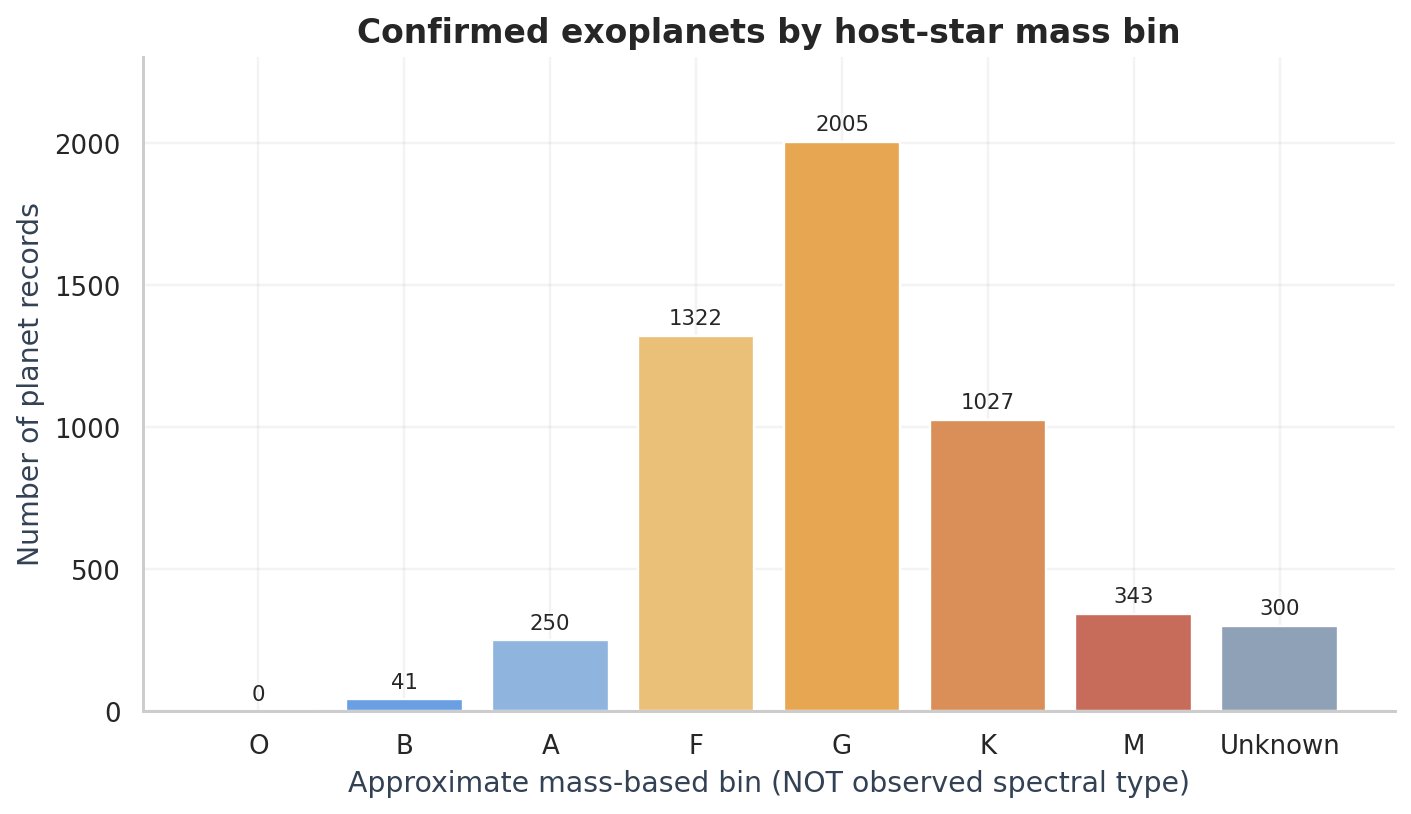

In [5]:
display(Image(filename=str(ROOT/'figures/01_stellar_mass_bins.png'), width=820))

## 6 · Stellar mass and temperature: one point per host-system proxy

A star hosting several planets must not be plotted several times and then interpreted as several distinct stars. The scatter is deduplicated using sky coordinates where available. Coordinates are **only a proxy** for unique host systems, not a guaranteed stellar identifier.

The reversed temperature axis follows an astronomical convention, while the y-axis is logarithmic.

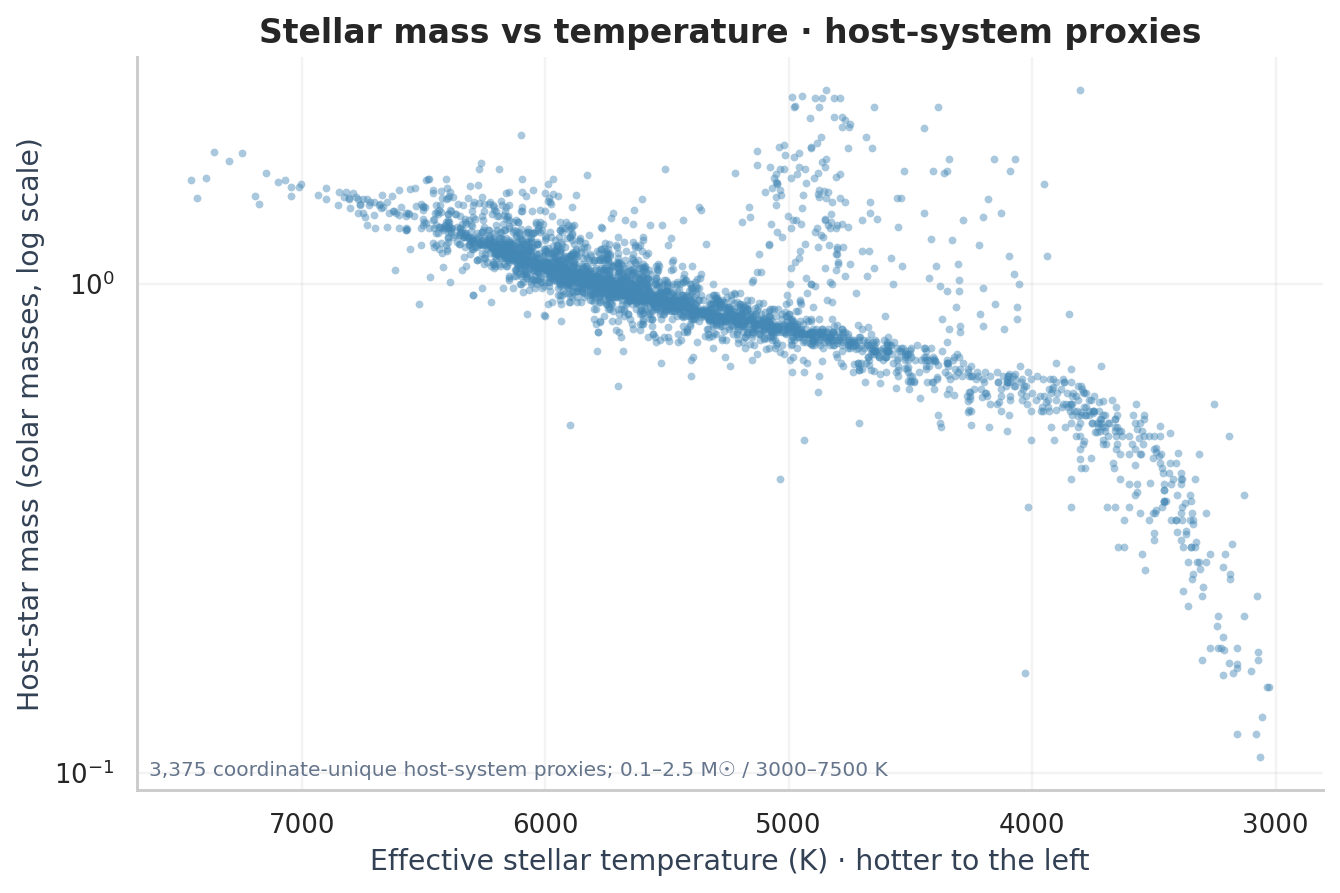

In [6]:
display(Image(filename=str(ROOT/'figures/02_stellar_scatter.png'), width=820))

## 7 · Three-state outcome: inside, outside or insufficient data

The original boolean `True/False` classification unintentionally treated all missing inputs as `False`. Here we show three separate categories, so the 3,112 unassessable confirmed exoplanets do **not** inflate the outside-HZ count.

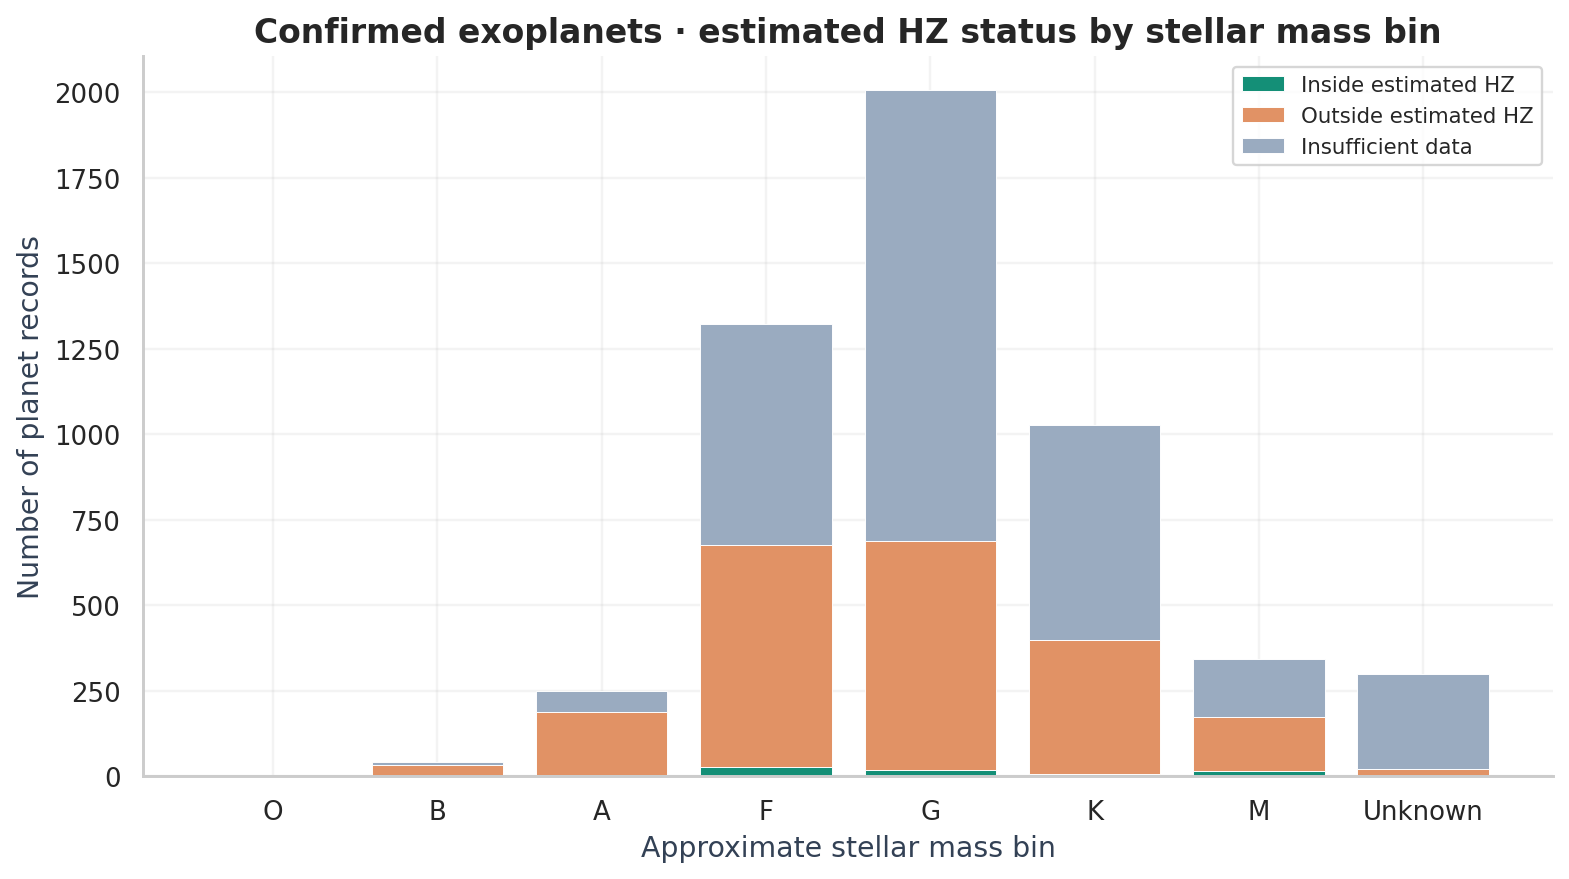

In [7]:
display(Image(filename=str(ROOT/'figures/03_hz_status_by_mass_bin.png'), width=820))

## 8 · Seaborn heatmap

This heatmap **colours the share within evaluable records of each mass bin**, while the printed labels show **raw counts**. Its two categories exclude the missing-data class from their denominator. The underlying calculation is implemented using a `groupby`, `unstack` and Seaborn `heatmap`.

In [8]:
# Rebuild the heatmap directly in the notebook (no pre-rendered image needed).
import matplotlib.pyplot as plt
import seaborn as sns

status_columns = ['Inside estimated HZ', 'Outside estimated HZ']
evaluable = summary[status_columns].sum(axis=1)
conditional_pct = (100 * summary[status_columns]
                   .div(evaluable.replace(0, np.nan), axis=0)).round(1)
print('Within-bin percentages (only evaluable records):')
display(conditional_pct)

fig, ax = plt.subplots(figsize=(9.4, 5.6))
sns.heatmap(conditional_pct, cmap='YlGnBu', vmin=0, vmax=100,
            annot=summary[status_columns].astype(str), fmt='',
            linewidths=0.6, linecolor='white',
            cbar_kws={'label': 'Percentage of evaluable exoplanets'}, ax=ax)
ax.set(title='Inside / outside the simplified HZ by stellar mass bin',
       xlabel='HZ status (annotation = raw planet count)',
       ylabel='Approximate stellar mass bin')
ax.set_xticklabels(['Inside HZ', 'Outside HZ'], rotation=0)
fig.tight_layout()
plt.show()

Within-bin percentages (only evaluable records):


hz_status,Inside estimated HZ,Outside estimated HZ
stellar_mass_bin,,
O,NaN,NaN
B,0.0,100.0
A,2.1,97.9
F,4.0,96.0
G,2.8,97.2
K,1.3,98.7
M,8.7,91.3
Unknown,0.0,100.0


/tmp/ipykernel_3245/464408540.py:22: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



## 9 · Orbital distance, stellar luminosity and incident flux

The green interval shows the *mathematical* region resulting from the fixed irradiance thresholds. Its appearance is not proof of surface habitability. Orbital eccentricity is not included, and many candidates could be gas giants.

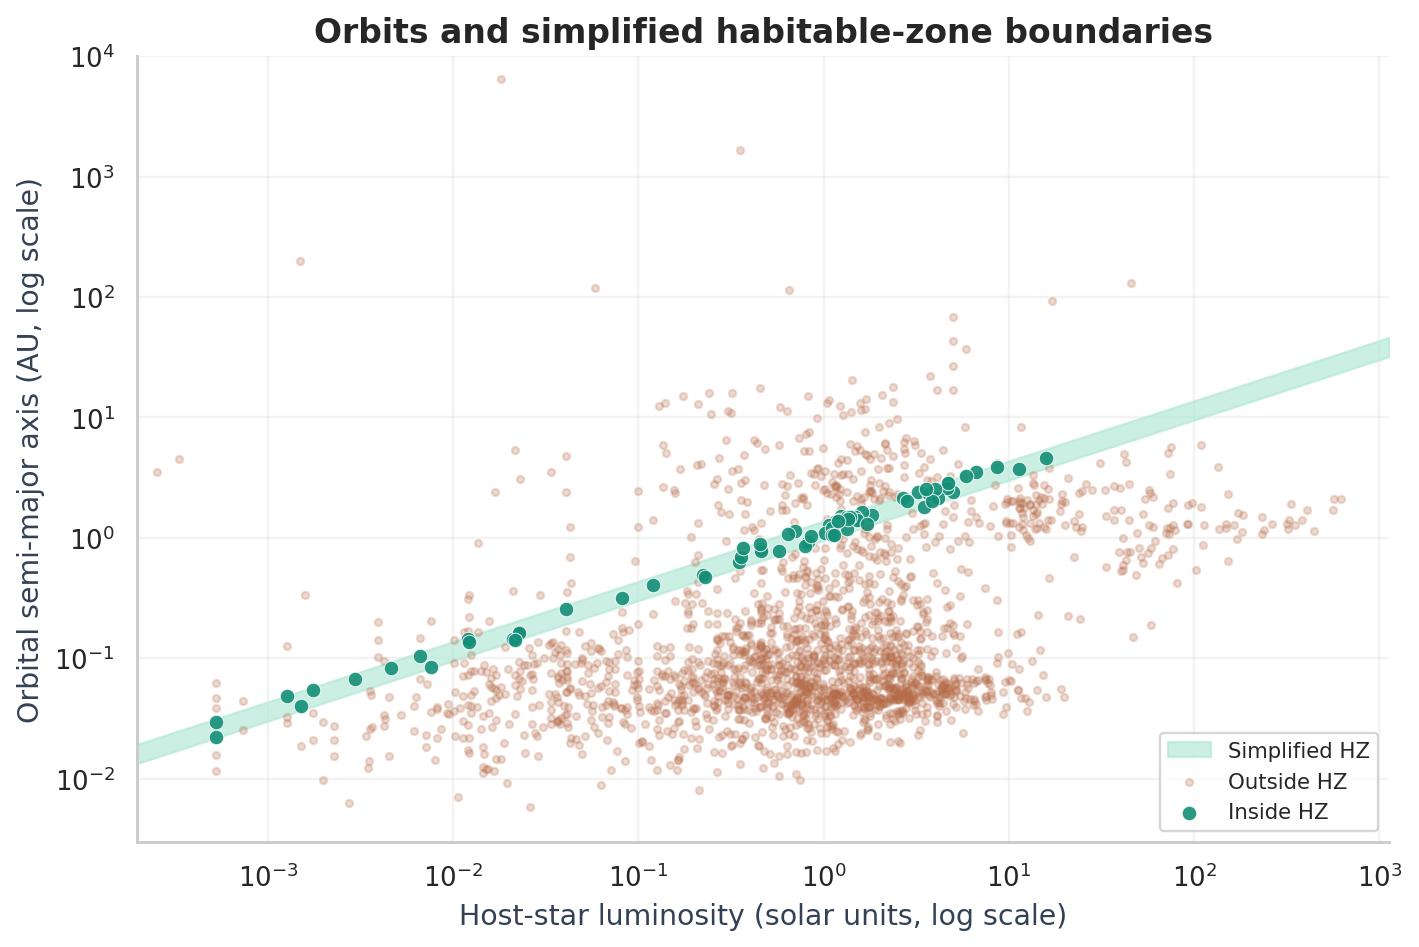

In [9]:
display(Image(filename=str(ROOT/'figures/06_orbital_distance_vs_luminosity.png'), width=820))

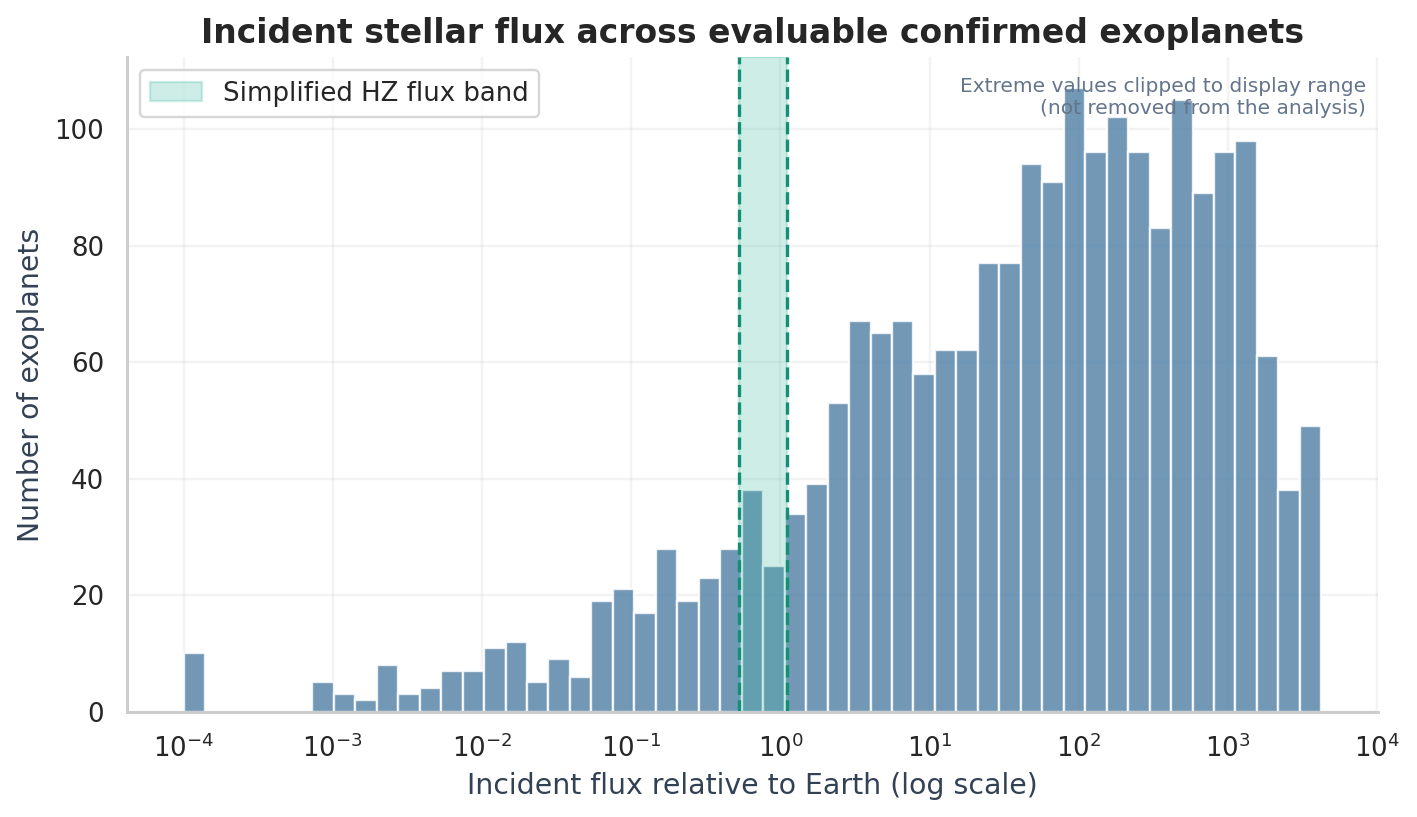

In [10]:
display(Image(filename=str(ROOT/'figures/05_incident_flux_distribution.png'), width=820))

## 10 · Interactive Plotly treemap and scatter

The revised treemap summarises counts by approximate stellar mass bin and the three HZ categories, rather than displaying thousands of tiny planet-name boxes. Files are **offline HTML**; download and open in any browser to explore hover and zoom.

- [`interactive_treemap.html`](../figures/interactive_treemap.html)
- [`interactive_stellar_scatter.html`](../figures/interactive_stellar_scatter.html)

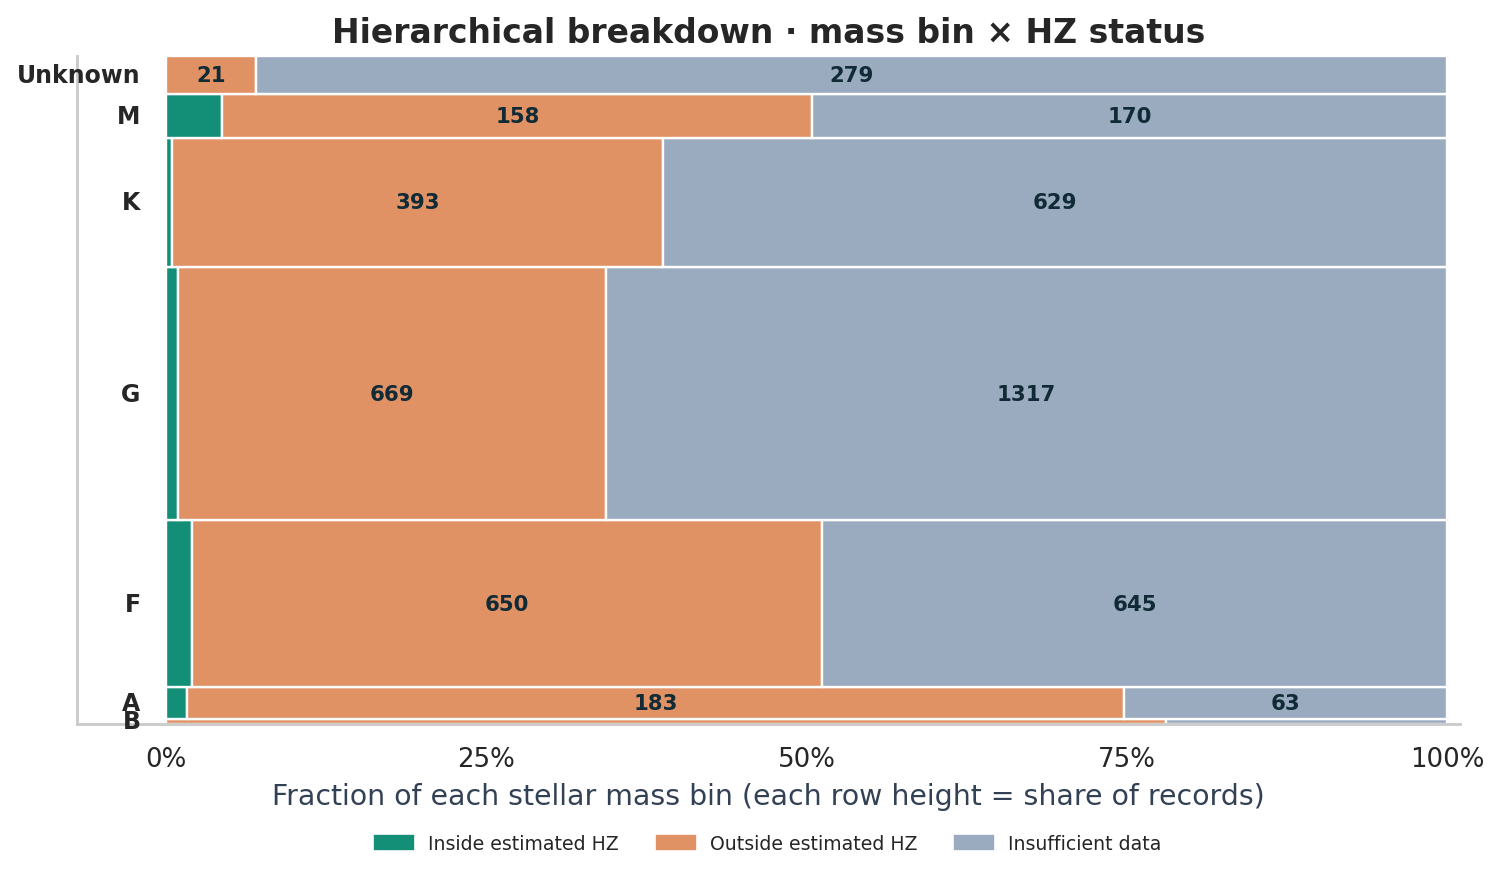

In [11]:
# Interactive treemap: display in Jupyter; the static preview below is
# included so GitHub viewers can see the idea even without interactive JS.
import plotly.express as px
plot_data = (summary.stack().reset_index(name='planets')
             .rename(columns={'hz_status':'classification'}))
plot_data = plot_data[plot_data['planets'] > 0]
fig = px.treemap(plot_data,
                 path=[px.Constant('Confirmed exoplanets'),
                       'stellar_mass_bin', 'classification'],
                 values='planets', color='classification',
                 title='Confirmed exoplanets: approximate host mass × HZ status')
fig.update_traces(textinfo='label+value+percent parent')
fig.show()
display(Image(filename=str(ROOT/'figures/08_treemap_static_preview.png'), width=820))

## 11 · Observational limitations

Detection methods affect the observed sample. Transit and radial-velocity techniques have selection biases, so this dataset should **not** be used to infer the frequency of habitable-zone planets in the galaxy.

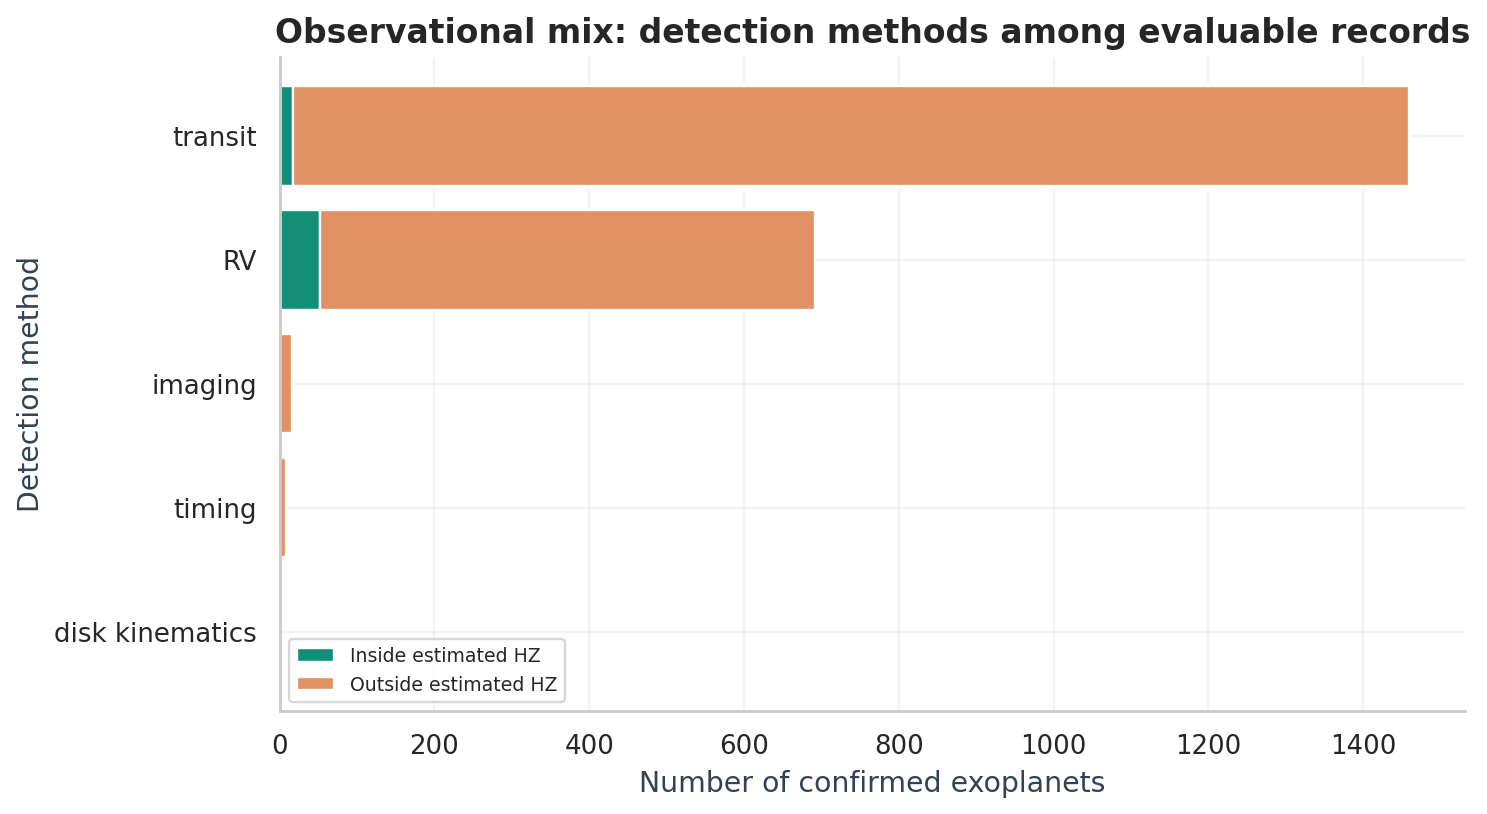

In [12]:
display(Image(filename=str(ROOT/'figures/07_discovery_methods.png'), width=820))

## 12 · Conclusions and next steps

The provided snapshot contains **5,288 confirmed exoplanet records**, but only **2,176** have the three positive, finite inputs necessary to evaluate the selected luminosity-scaled zone. **70** lie inside that **simplified geometric interval**, **2,106** lie outside and **3,112** lack sufficient data.

**The result is conditional on the evaluable, selected catalogue records, not a physical estimate of habitable exoplanet occurrence.** A large number of missing parameters and observational biases limit its interpretation. Many hits may be gaseous planets, have eccentric orbits, belong to binary systems, or have atmospheres incompatible with surface liquid water.

This analysis could be improved with temperature-dependent habitable-zone flux prescriptions, orbital eccentricity modelling, better host-star IDs, uncertainty propagation, and updated catalogues. These are **proposed future extensions**, not implemented in the current project.

**Attribution:** [Open Exoplanet Catalogue](https://github.com/OpenExoplanetCatalogue/oec_tables). Additional discussion of HZ modelling: [Kopparapu et al. (2014)](https://doi.org/10.1088/2041-8205/787/2/L29).